# Лабораторная работа № 1.3 
# Дополнительная работа
---
«Кластерный анализ» 

Рязанцев Георгий Борисович

# Самостоятельная работа
---

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [17]:


df = pd.read_csv('Customers.csv', sep=";", decimal=",") 
df[['Prices', 'Number', 'Customer_id']] = df[['Prices', 'Number', 'Customer_id']].astype(float)

df = df[(df['Prices'] < 100000) & (df['Prices'] > 00)] # фильтр выбросов и недопустимых значений по Prices

df["DateTime"] = pd.to_datetime(df["Date"], format="%d.%m.%Y", errors="coerce") #удобный формат даты

df["days"] = (df["DateTime"] - df["DateTime"].min()).dt.days + 1 # на каком дню, от начала записей была совершена покупка

df = df.sort_values("Customer_id")
df = df.dropna()

df.head()

,Number,Customer_id,Prices,Date,DateTime,days
759130,3203041.0,0.0,494.2,08.12.2018,2018-12-08,342.0
3300,1241821.0,1.0,2799.3,04.01.2018,2018-01-04,4.0
783307,3281813.0,76.0,1248.1,13.12.2018,2018-12-13,347.0
360540,2073453.0,90.0,1190.0,16.07.2018,2018-07-16,197.0
586687,2687117.0,91.0,1397.2,20.10.2018,2018-10-20,293.0


In [18]:
customer_data = df.groupby("Customer_id").agg(      #группировка по айди, т.к. сам айди служит только для идентифицирования покупателя и доп. информации о покупке не несет
    last_day=("days", "max"), # агрегированные значения заносятся в отдельную колонку
    first_day=("days", "min"),
    mean_price=("Prices", "mean"),
    total_price=("Prices", "sum"),
    purchase_count=("Prices", "count")
).reset_index()

#значение по last_day менее понятно для человека, т.к. мы не всегда знаем какое максимальное
customer_data["since_last"] = customer_data["last_day"].max() - customer_data["last_day"] # вычисляет кол-во дней с последней покупки

customer_data = customer_data.drop(columns=["last_day"]) # удаляем чтобы избежать дублирующей информации

customer_data.head()

,Customer_id,first_day,mean_price,total_price,purchase_count,since_last
0,0.0,342.0,494.200000,494.2,1,95.0
1,1.0,4.0,2799.300000,2799.3,1,433.0
2,76.0,347.0,1248.100000,1248.1,1,90.0
3,90.0,197.0,1190.000000,1190.0,1,240.0
4,91.0,110.0,1289.633333,3868.9,3,144.0


In [19]:
from sklearn.preprocessing import StandardScaler

features = [
    "first_day",
    "since_last",
    "purchase_count",
    "mean_price",
    "total_price"
]

npdata = customer_data[features]

scaler = StandardScaler()
data = scaler.fit_transform(npdata)


In [25]:
data = pd.DataFrame(data, columns=features)
data.head()

,first_day,since_last,purchase_count,mean_price,total_price
0,0.788324,-0.569801,-0.109469,-0.588565,-0.144055
1,-1.875506,2.228677,-0.109469,0.194558,-0.054200
2,0.827730,-0.611199,-0.109469,-0.332439,-0.114667
3,-0.354443,0.630729,-0.109469,-0.352177,-0.116932
4,-1.040104,-0.164105,0.117215,-0.318328,-0.012506


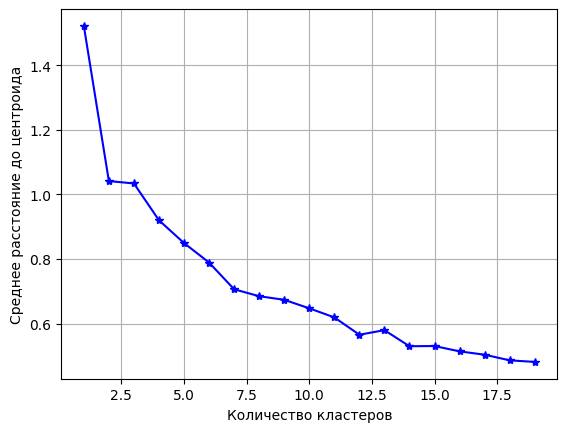

In [21]:
from scipy.spatial import distance
from sklearn import cluster 

cdata = data
K = range(1, 20)
KM = (cluster.KMeans(n_clusters=k).fit(cdata) for k in K)
centroids = (k.cluster_centers_ for k in KM)

D_k = (distance.cdist(cdata, cent, 'euclidean') for cent in centroids)
dist = (np.min(D, axis=1) for D in D_k)
avgWithinSS = [sum(d) / cdata.shape[0] for d in dist]

plt.plot(K, avgWithinSS, 'b*-')
plt.grid(True)
plt.xlabel('Количество кластеров')
plt.ylabel('Среднее расстояние до центроида')
plt.show()

Оптимальное кол-во кластеров — 7

In [44]:
n_clusters = 7
means_cluster = cluster.KMeans(n_clusters=n_clusters, random_state=111)
columns = ["first_day", "since_last", "purchase_count", "mean_price", "total_price"]

est = means_cluster.fit(data[columns])
clusters = est.labels_
data['cluster'] = clusters
customer_data["cluster"] = clusters

In [50]:
for c in range(n_clusters):
    cluster_members=data[customer_data['cluster'] == c] [:]
    print('Cluster{}(n={}):'.format(c, len(cluster_members)))
print(customer_data.drop(columns="Customer_id").groupby(['cluster']).mean().round())

Cluster0(n=256539):
Cluster1(n=159537):
Cluster2(n=24):
Cluster3(n=13507):
Cluster4(n=45581):
Cluster5(n=55418):
Cluster6(n=1790):
         first_day  mean_price  total_price  purchase_count  since_last
cluster                                                                
0            336.0      1325.0       1792.0             1.0        93.0
1            107.0      1661.0       2172.0             1.0       321.0
2             52.0      2943.0    3364661.0          1144.0        23.0
3            231.0     12845.0      17565.0             1.0       190.0
4             94.0      1845.0      14528.0             8.0        77.0
5            319.0      4852.0       6789.0             1.0       106.0
6            259.0     30188.0      37937.0             1.0       171.0


In [ ]:
customer_data[customer_data["cluster"] == 2]

,Customer_id,first_day,mean_price,total_price,purchase_count,since_last,cluster
253,11508.0,131.0,2710.498331,1948848.3,719,0.0,2
426,16721.0,11.0,2487.421534,3211261.2,1291,7.0,2
1010,39506.0,11.0,4018.050621,6143599.4,1529,0.0,2
2047,53832.0,23.0,2816.333057,4421642.9,1570,1.0,2
6955,125090.0,11.0,3023.186462,2367155.0,783,195.0,2
9571,154900.0,4.0,2730.460905,3317510.0,1215,1.0,2
9659,155823.0,2.0,2933.609160,2690119.6,917,19.0,2
12652,186744.0,6.0,2698.872876,4129275.5,1530,0.0,2
14310,201960.0,8.0,2486.555735,3230035.9,1299,9.0,2
16554,221047.0,4.0,2757.994842,3742599.0,1357,1.0,2


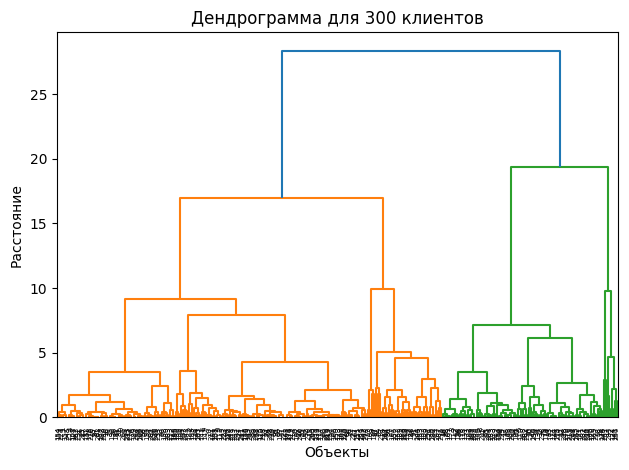

In [39]:
from scipy.cluster.hierarchy import linkage, dendrogram

sample = data.sample(300, random_state=111)

linked = linkage(sample, method='ward')

fig, ax = plt.subplots()

dendrogram(linked, ax=ax)

ax.set_title('Дендрограмма для 300 клиентов')
ax.set_xlabel('Объекты')
ax.set_ylabel('Расстояние')

plt.tight_layout()
plt.show()